# scPDB ligand types: before vs. after enhancement

- **Before**: `full_scPDB.csv`, one row per (pdb, chain) pocket. Its ligand column is always
  the literal string `UNKNOWN` (no per-row ligand code), so the ligand is looked up via
  `original_scPDB_pdb_to_ligand.pkl` (pdb -> original ligand).
- **After**: `scPDB-sites.csv`, one row per (pdb, chain, ligand) — the same physical site
  can appear multiple times. Rows are merged per (pdb, chain) with `get_binding_site_clusters`;
  `UNKNOWN` ligands are decoded the same way, and every distinct ligand within a cluster is
  counted (a site can be promiscuous, i.e. bind more than one ligand type).

In [8]:
import sys
import pickle
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append('/home/skrhakv/Projects/seq2pocket/src/utils')
from extraction_utils import get_binding_site_clusters

DATA_DIRECTORY = '/home/skrhakv/Projects/seq2pocket/data/data-extraction'
STATS_DIRECTORY = '/home/skrhakv/Projects/seq2pocket/data/stats'

before_df = pd.read_csv(f'{DATA_DIRECTORY}/full_scPDB.csv', sep=';', header=None,
                         names=['pdb', 'chain', 'ligand', 'residues', 'sequence'])

after_df = pd.read_csv(f'{DATA_DIRECTORY}/scPDB-sites.csv', sep=';', header=None,
                        names=['pdb', 'chain', 'ligand', 'residues'])
after_df['residues'] = after_df['residues'].apply(str.split)

with open(f'{STATS_DIRECTORY}/original_scPDB_pdb_to_ligand.pkl', 'rb') as f:
    pdb_to_ligand = pickle.load(f)

def decode(pdb: str, ligand: str) -> str:
    return pdb_to_ligand.get(pdb, ligand) if ligand == 'UNKNOWN' else ligand

In [9]:
before_counts = pd.Series([decode(pdb, ligand) for pdb, ligand in zip(before_df['pdb'], before_df['ligand'])]).value_counts()

def cluster_ligand_sets(group: pd.DataFrame) -> list[set[str]]:
    """Cluster a (pdb, chain) group's binding sites and, for each cluster, return the
    set of distinct ligands bound there (UNKNOWN decoded via the original scPDB mapping)."""
    pdb = group['pdb'].iloc[0]
    if len(group) == 1:
        return [{decode(pdb, group['ligand'].iloc[0])}]
    clusters = get_binding_site_clusters(group['residues'].tolist())
    if clusters is None:
        return [{decode(pdb, ligand)} for ligand in group['ligand']]
    labels = clusters.flatten()
    return [{decode(pdb, ligand) for ligand in group['ligand'][labels == cluster_id]} for cluster_id in set(labels)]

site_clusters = [ligand_set for _, group in after_df.groupby(['pdb', 'chain']) for ligand_set in cluster_ligand_sets(group)]
after_ligands = [ligand for ligand_set in site_clusters for ligand in ligand_set]
after_counts = pd.Series(after_ligands).value_counts()

print(f'before: {len(before_df)} pockets, after: {len(after_df)} rows merged into {len(site_clusters)} sites ({len(after_ligands)} ligand mentions)')

before: 17077 pockets, after: 149869 rows merged into 56899 sites (109410 ligand mentions)


In [10]:
n_ligand_types = pd.Series([len(s) for s in site_clusters])
n_promiscuous = (n_ligand_types > 1).sum()

print(f'{n_promiscuous} / {len(n_ligand_types)} merged sites ({n_promiscuous / len(n_ligand_types):.1%}) '
      'bind more than one distinct ligand type')
print(n_ligand_types.value_counts().sort_index().rename('n sites').rename_axis('distinct ligand types'))

13206 / 56899 merged sites (23.2%) bind more than one distinct ligand type
distinct ligand types
1      43693
2       7628
3       2310
4        947
5        461
6        330
7        146
8         67
9        127
10       113
11       192
12        25
13       125
14        43
15        15
16        24
17        64
18       116
19        22
20        23
21        21
22         2
24        35
25        24
26         2
27        21
28         1
29         8
30        11
31        10
32         1
33        42
34        12
35        59
36         4
37        10
38         1
43         8
45         1
46        11
47         3
54         9
63         1
88         1
90         3
91        60
92        50
93         8
121        1
152        2
180        1
182        2
183        1
269        1
270        1
Name: n sites, dtype: int64


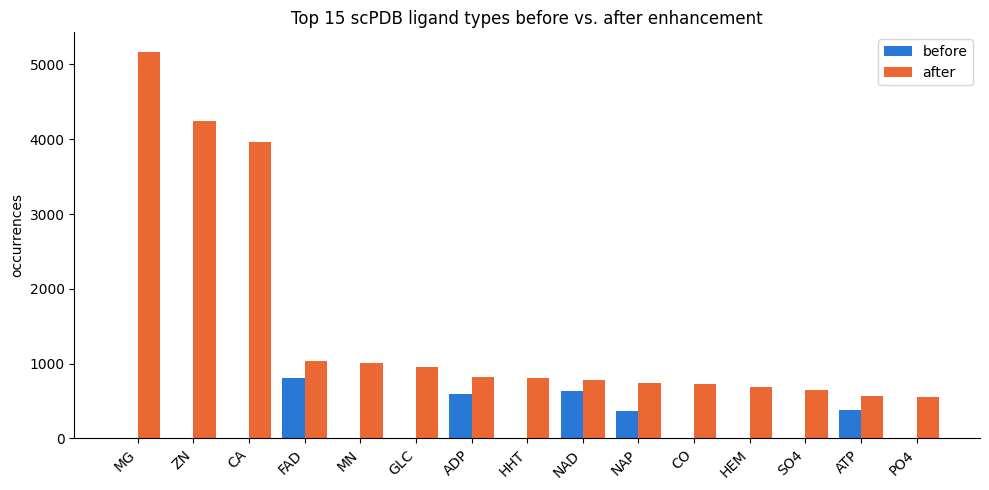

In [12]:
TOP_N = 15
top_ligands = after_counts.head(TOP_N).index
counts = pd.DataFrame({'before': before_counts, 'after': after_counts}).loc[top_ligands].fillna(0)

x = range(len(counts))
width = 0.4
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar([i - width / 2 for i in x], counts['before'], width, label='before', color='#2a78d6')
ax.bar([i + width / 2 for i in x], counts['after'], width, label='after', color='#eb6834')
ax.set_xticks(list(x))
ax.set_xticklabels(counts.index, rotation=45, ha='right')
ax.set_ylabel('occurrences')
ax.set_title(f'Top {TOP_N} scPDB ligand types before vs. after enhancement')
ax.spines[['top', 'right']].set_visible(False)
ax.legend()
fig.tight_layout()

findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: F

[]

findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.


findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: Font family 'Archivo' not found.
findfont: F

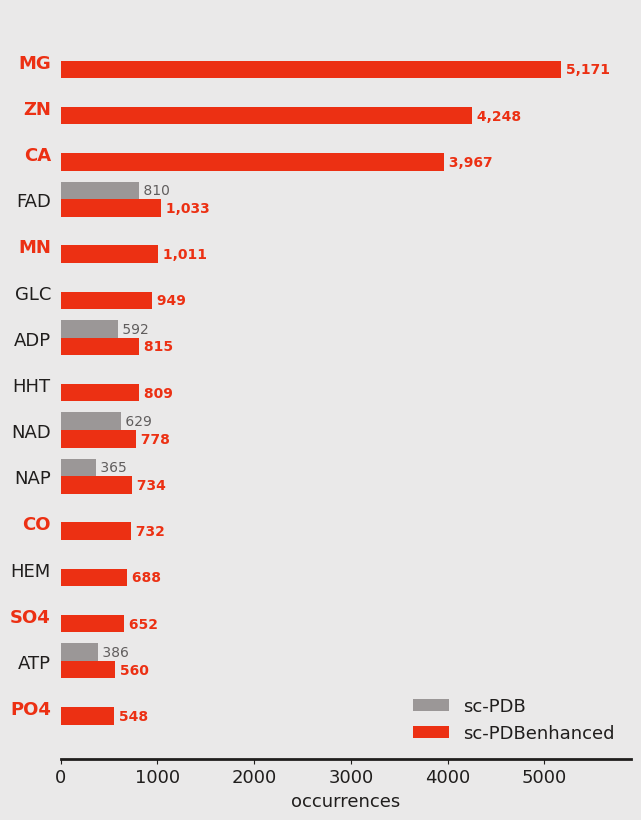

In [16]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager

# ── Modernist palette ───────────────────────────────────────────────
BG      = "#eae9e9"   # ground
INK     = "#201e1d"   # text / axis
BEFORE  = "#9b9797"   # neutral-500
AFTER   = "#ec3013"   # accent red
MUTED   = "#605d5d"   # neutral-700

# Archivo to match the poster. Point matplotlib at a local .ttf if you have it:
#   font_manager.fontManager.addfont("Archivo-Regular.ttf")
#   font_manager.fontManager.addfont("Archivo-Bold.ttf")
mpl.rcParams.update({
    "font.family":      "Archivo",       # falls back to sans if unavailable
    "font.size":        13,
    "axes.edgecolor":   INK,
    "axes.linewidth":   2,               # 2px rules
    "text.color":       INK,
    "axes.labelcolor":  INK,
    "xtick.color":      INK,
    "ytick.color":      INK,
    "svg.fonttype":     "none",          # keep text as editable text in SVG
    "figure.facecolor": BG,
    "axes.facecolor":   BG,
})

# ── data: top-N by the enhanced (after) counts ──────────────────────
TOP_N = 15
top_ligands = after_counts.head(TOP_N).index
counts = (pd.DataFrame({"before": before_counts, "after": after_counts})
            .loc[top_ligands].fillna(0))
counts = counts.iloc[::-1]               # largest on top for barh

# mark which codes are ions so their labels read in red (edit to your set)
IONS = {"ZN","MG","CA","NA","K","MN","FE","FE2","CU","CO","NI","CD",
        "HG","CL","IOD","BR","SO4","PO4","NH4","CS","SR","BA"}

y = range(len(counts))
h = 0.38
fig, ax = plt.subplots(figsize=(6.6, 8.4))   # tall — fits a poster column

ax.barh([i + h/2 for i in y], counts["before"], h, label="sc-PDB",
        color=BEFORE, zorder=3)
ax.barh([i - h/2 for i in y], counts["after"],  h, label="sc-PDBenhanced",
        color=AFTER,  zorder=3)

# value labels at bar ends
for i, (b, a) in enumerate(zip(counts["before"], counts["after"])):
    if b: ax.text(b, i + h/2, f" {int(b):,}", va="center", ha="left",
                  fontsize=10, color=MUTED)
    if a: ax.text(a, i - h/2, f" {int(a):,}", va="center", ha="left",
                  fontsize=10, color=AFTER, fontweight="bold")

ax.set_yticks(list(y))
ax.set_yticklabels(counts.index)
for tick, code in zip(ax.get_yticklabels(), counts.index):   # red ion labels
    if code in IONS:
        tick.set_color(AFTER); tick.set_fontweight("bold")

ax.set_xlabel("occurrences")
ax.margins(x=0.14)                        # room for the value labels
ax.spines[["top", "right"]].set_visible(False)
ax.spines["left"].set_visible(False)
ax.tick_params(left=False)                # flush-left labels, no left rule
ax.legend(frameon=False, loc="lower right")

fig.tight_layout()
plt.plot()
# fig.savefig("ligand_before_after.svg", facecolor=BG, bbox_inches="tight")
# fig.savefig("ligand_before_after.pdf", facecolor=BG, bbox_inches="tight")